# WP12 küçük pilot: insan inceleme konsolidasyonu ve S16 hazırlığı

İki kullanıcı PDF’si, 44 frozen alıntı ve 19 senaryo korunur. Üç bağımsız prospektüs veya klinik doğrulama yoktur. Teknik schema PASS, semantik doğruluk oranı değildir. Yeni API çağrısı yok.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S16_preparation_v1'
t=pd.read_csv(Q/'consolidated_source_claim_review.csv')
with pd.option_context('display.max_colwidth',None):display(t)

,scenario,item,physical_page,primary_quote_id,source_quote_exact,model_explanation_exact,agent_source_status,agent_note_tr,Turkish_review,citation_scope,uncertainty_exception,human_decision,automatic_release,prior_table_ref
0,S01,1,1,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,"The name of your medicine is Erythromycin Tablets BP 250 mg (referred to as \nErythromycin Tablets in this leaflet). Erythromycin Tablets contain the active ingredient \nerythromycin, which belongs to a group of medicines called macrolide antibiotics. \n \n",İlacın adı Erythromycin Tablets BP 250 mg’dir ve etkin madde eritromisindir.,SUPPORTED_PENDING_HUMAN,Tam ürün adı ve etkin madde kaynakta mevcut; macrolide sınıfı aktarılmamış.,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
1,S01,2,6,quote:e9288119add1a9a49d1b3353510b966b508729035697e4afe9519f4af95aaeb5,"What Erythromycin Tablets look like and the contents of the pack \nErythromycin Tablets are red coloured, round, biconvex, enteric-coated tablets. \n \nThey are available in blister packs containing 28, 56, 84 and 100 tablets or in containers of \n21, 100, 250, 500 and 1000 tablets. \n \n","Erythromycin Tablets kırmızı renkli, yuvarlak, bikonveks ve enterik kaplı tabletlerdir.",SUPPORTED_PENDING_HUMAN,Kırmızı/yuvarlak/bikonveks/enterik kaplı özellikler kaynakta birebir; ambalaj adetleri aktarılmamış.,Kaynak uyumlu Türkçe; ayrıntı eksikleri,Mevcut birincil kaynak,Uygulanmaz: ürün kimliği,PENDING,False,reports\qa\WP12\openai_S01_success_review_v1\source_claim_comparison.csv
2,S07,1,7,quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,"Bu başlık, tetracyclines sınıfı için renal toksisite bağlamını verir: BUN artışı bildirilmiştir ve bunun dozla ilişkili olabileceği söylenir. Bu ifade sınıf düzeyindedir; tek başına doxycycline için bağımsız doğrudan kanıt olarak okunmamalıdır.",CORE_SUPPORTED_WITH_LANGUAGE_NOTE,tetracyclines sınıf adı İngilizce bırakılmış. BUN bildirimi ve dozla ilişkili olabileceği ifadesi sınıf kapsamında; doğrudan doxycycline kanıtı olmadığı belirtilmiş.,Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
3,S07,2,7,quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48,The following adverse reactions have been observed in patients receiving tetracyclines. \n,"Sınıf girişine göre sonraki advers reaksiyonlar tetracyclines alan hastalarda gözlenmiştir; bu, alt başlıktaki renal ifadenin sınıf bağlamında anlaşılması gerektiğini gösterir. Bu nedenle kayıt, tetracycline sınıfını doğrudan doxycycline'e eşitlemeden okunmalıdır.",CORE_CLASS_INTRO_SUPPORTED_CITATION_CONTEXT_NOTE,"İlk sınıf gözlemi doğrudan alıntıyla destekli. Renal alt başlık/doxycycline yorumu tüm girdi bağlamında destekleniyor; yalnız cite edilen sınıf-giriş cümlesi bu sözcükleri içermiyor. Bu, mevcut teknik kuralı değiştiren bir FAIL değildir; item düzeyinde atıf ayrıntısı için ajan inceleme notudur.",Tam Türkçe başarısı verilmedi; impaired renal function çevrilmemiş,Item2 atıf kapsamı notu; diğer bağlamlar tabloda,İstisnanın iki koşulu korunmuş; dil notu var,PENDING,False,reports\qa\WP12\openai_S07_actual_review_v1\source_claim_comparison.csv
4,S07,3,4,quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indicate that this does not occur \nwith the use of doxycycline in patients with impaired renal function. \n,"Tetracyclines’in antianabolik etkisi BUN artışına yol açabilir. Mevcut çalışmalara göre bu durum, impaired renal function olan hastala

**Yorum:** S01 kaynak uyumlu kimlik açıklamaları ve eksik ayrıntılar; S07 istisna anlamı yanında çevrilmemiş koşul ve atıf notu; S04 bilinmeyen sıklık yanında erken/usually/dilbilgisi notu ayrı. Tüm resmî insan kararları PENDING. Ajan notu insan adına karar değildir.

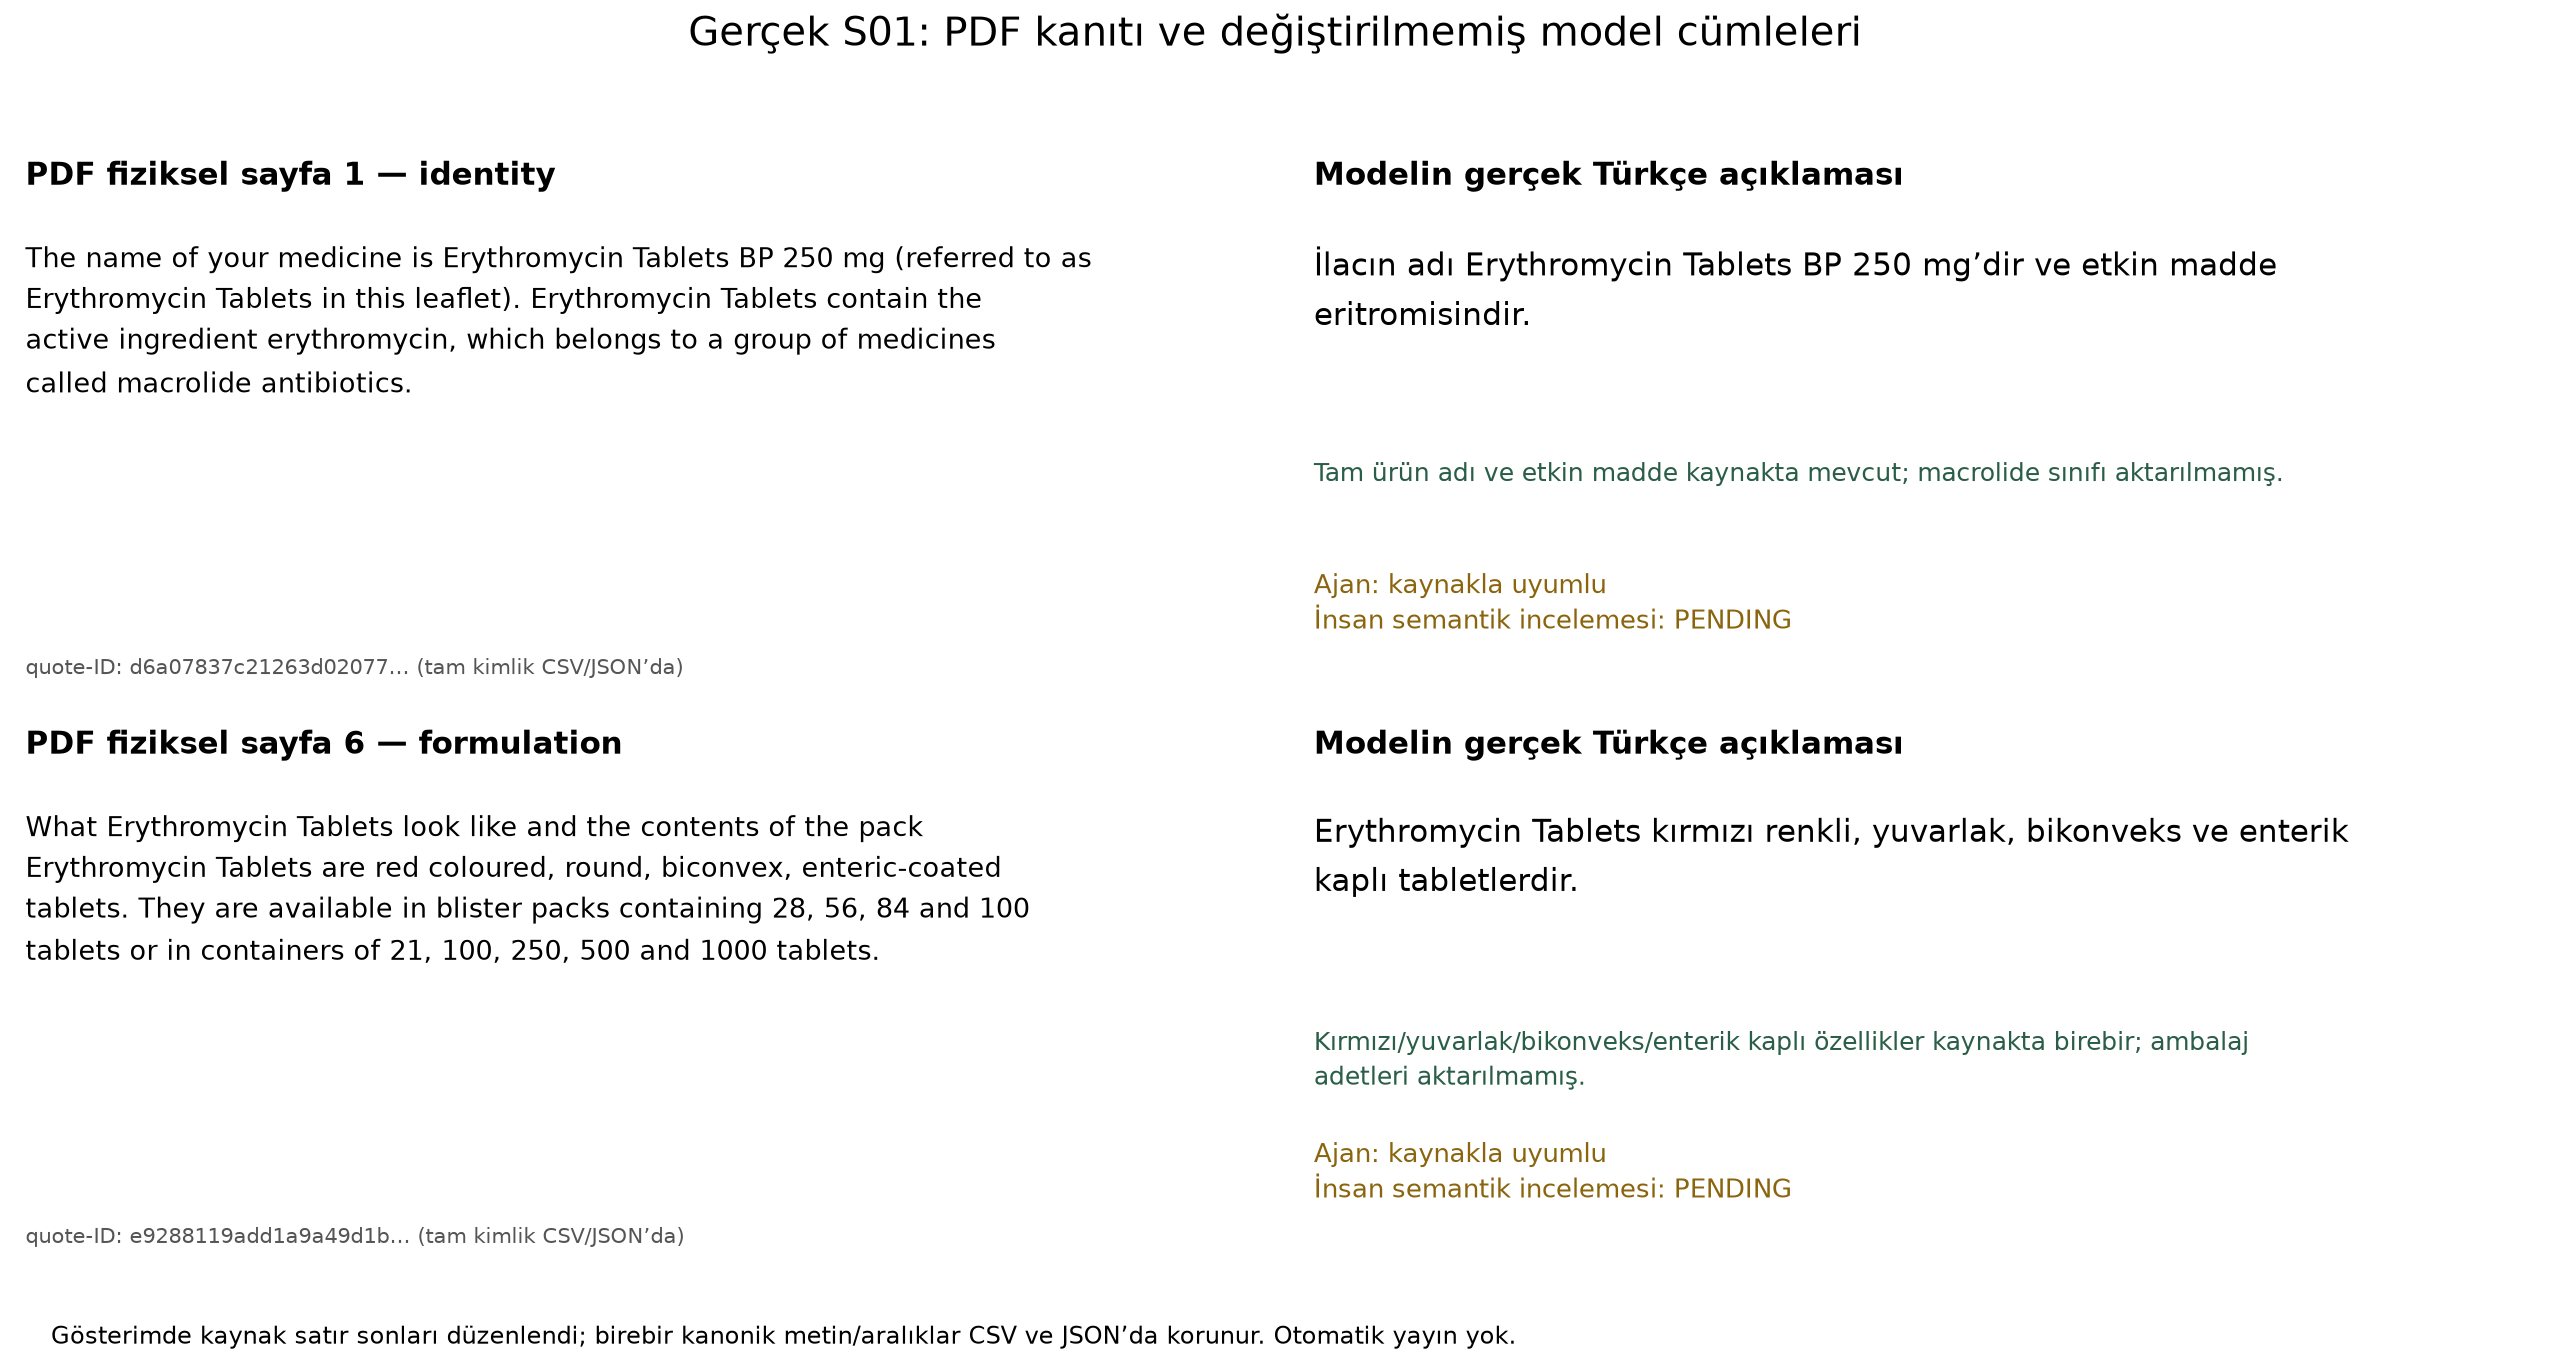

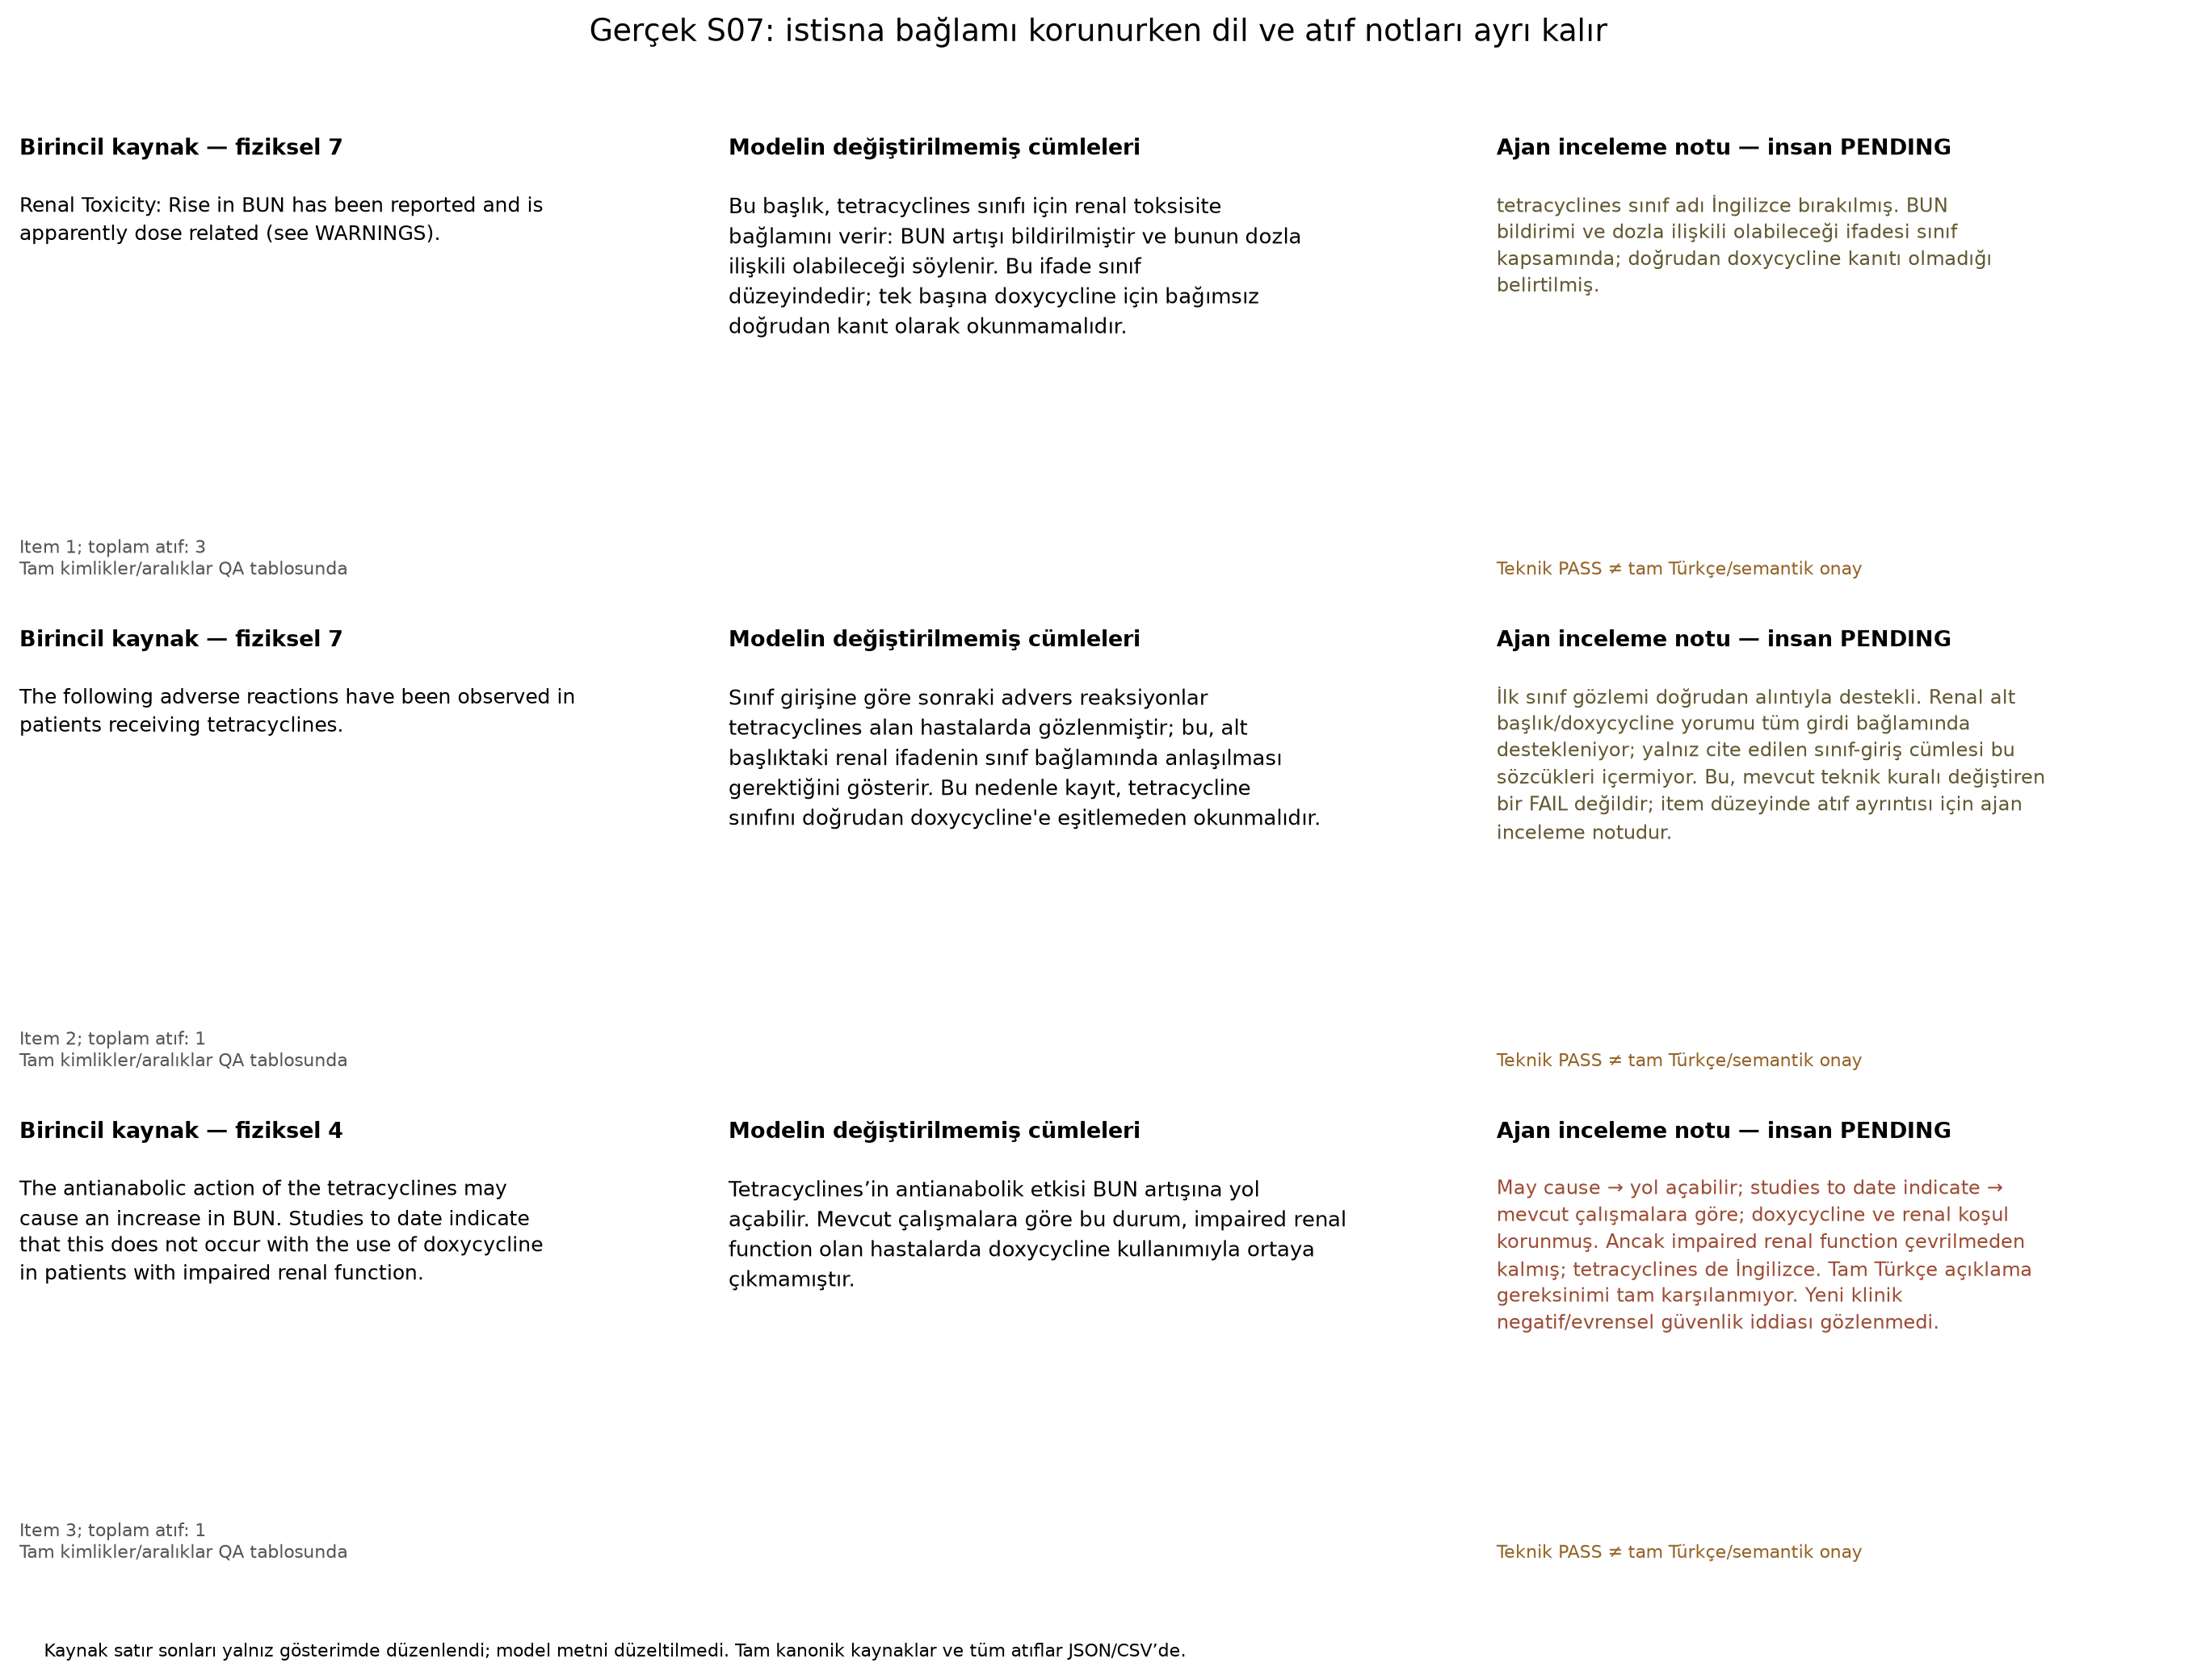

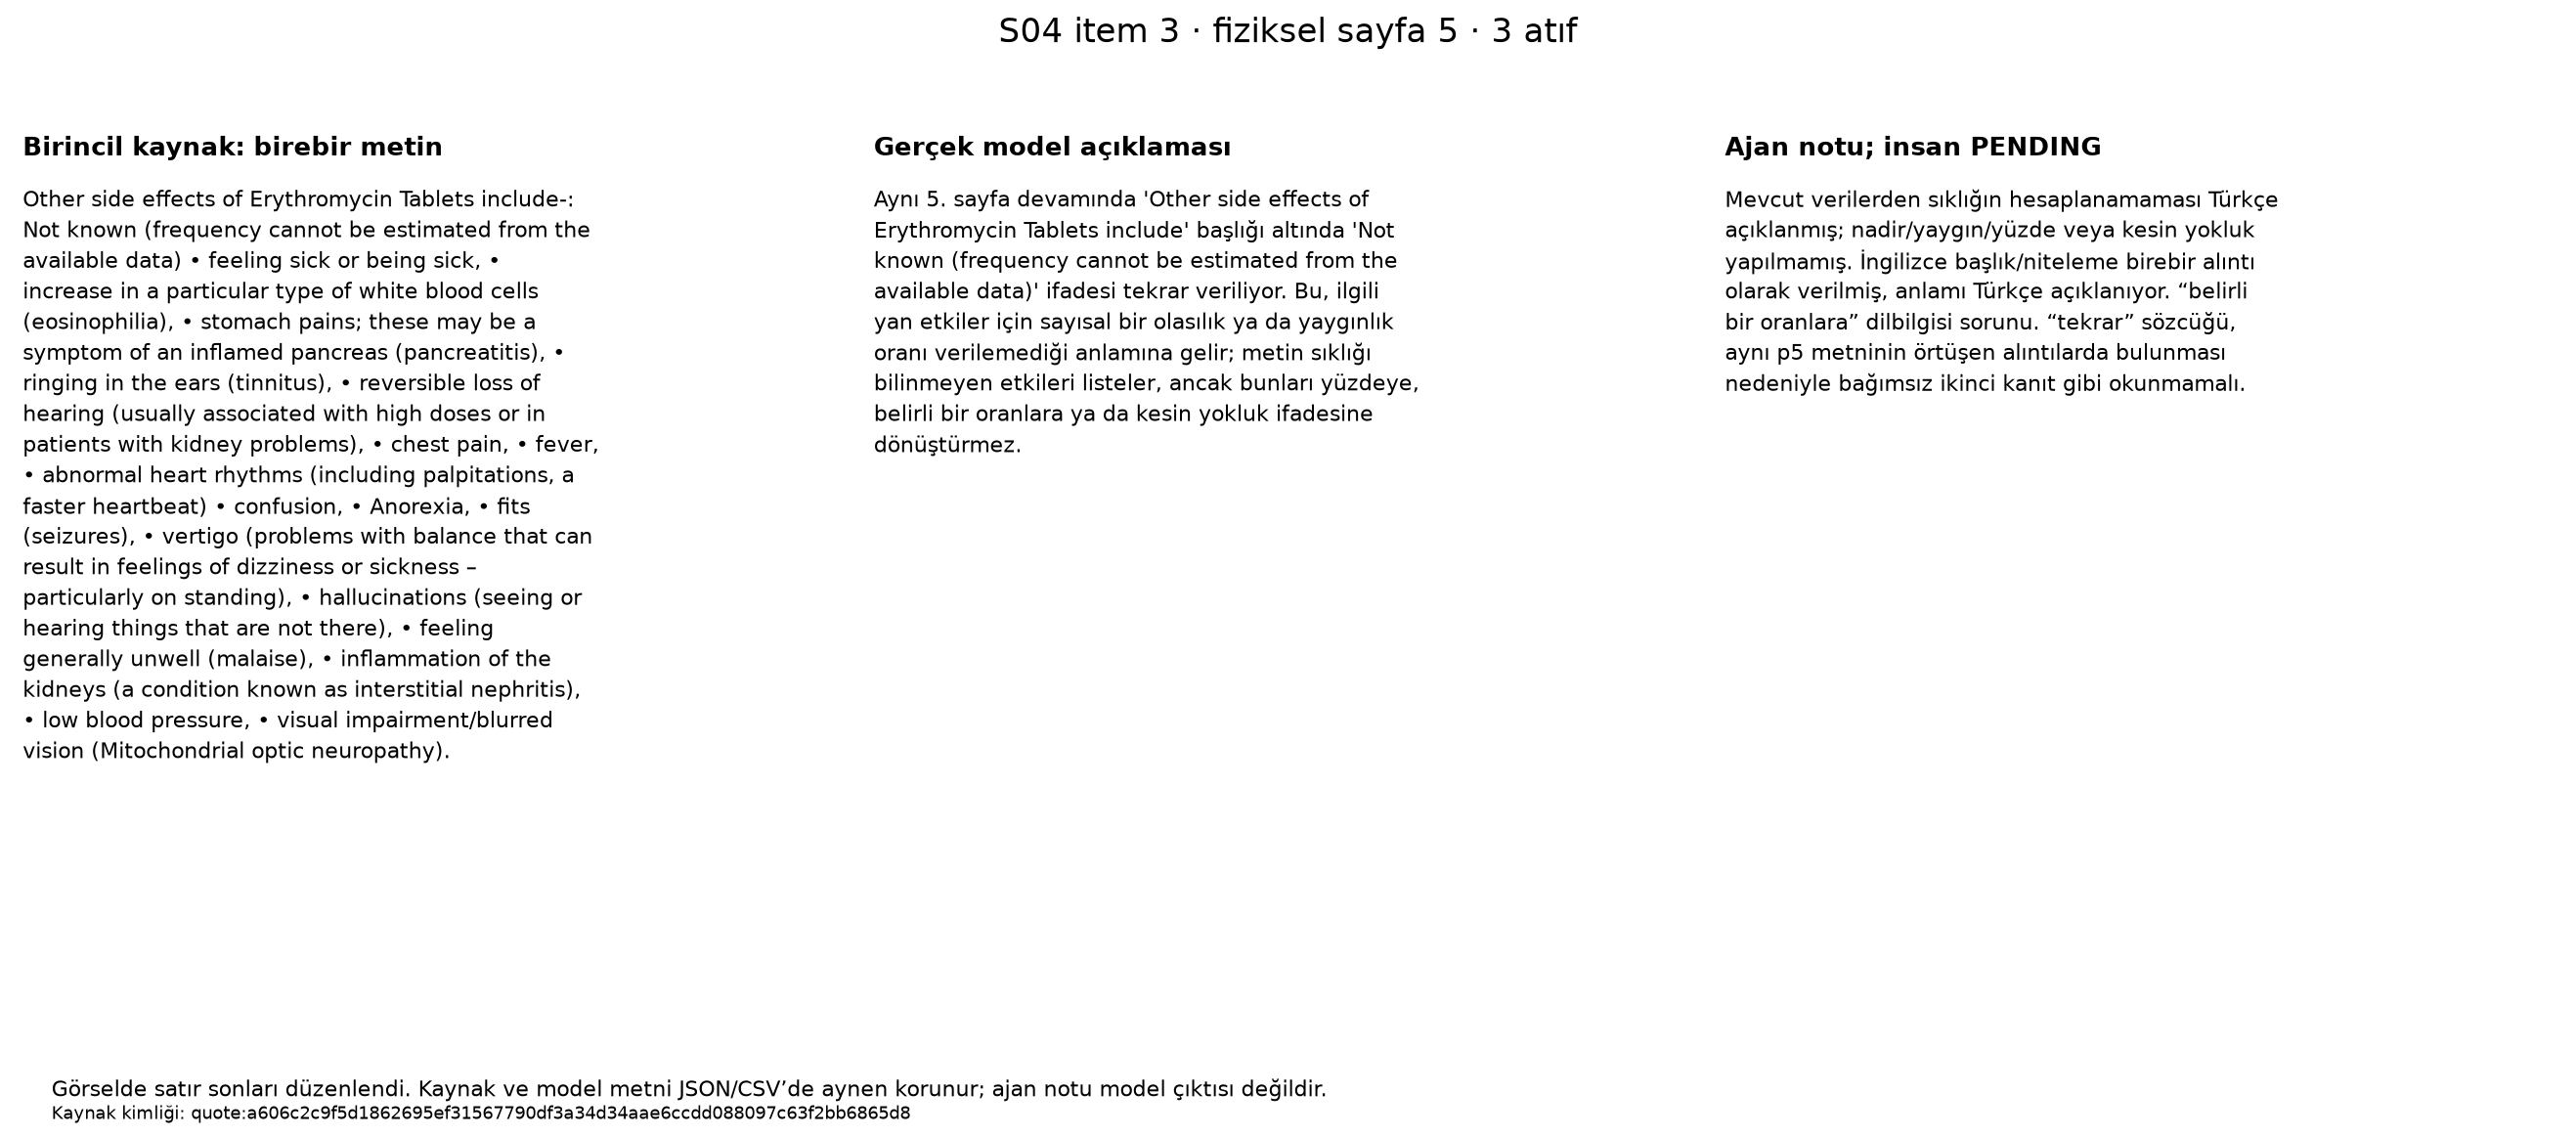

In [2]:
from IPython.display import Image
for path in ['openai_S01_success_review_v1/01_PDF_vs_real_claims.png','openai_S07_actual_review_v1/01_real_quotes_claims_and_flags.png','openai_S04_actual_review_v1/03_real_source_and_explanation.png']:
 display(Image(filename=str(ROOT/'reports/figures/WP12'/path)))


**Görsel yorumu:** Önceki gerçek kaynak/iddia görselleri salt okunur yeniden gösterilir; metin, model cevabı ve eski görsel dosyaları değiştirilmez. S04 üçüncü item, bilinmeyen sıklık örneğidir; bütün item’lar üst tabloda mevcut.

{
  "scenario_id": "S16",
  "question_tr": "Kaynak cümle ve sayfa olmadan bir yan etki özeti yaz.",
  "acceptance_criteria_tr": "REFUSE: NO_SOURCE; model belleğinden tamamlama yok.",
  "sources": []
}
{
  "actual_before": {
    "HTTP_reservations_total": 12,
    "inference_reservations_total": 4,
    "reserved_USD": "0.092",
    "within_limits": true,
    "unknown_prior_cost_not_refunded": true,
    "actual_invoice_total": "UNKNOWN_NOT_QUERIED"
  },
  "conditional_after_S16": {
    "HTTP_reservations_total": 15,
    "inference_reservations_total": 5,
    "reserved_USD": "0.115",
    "within_limits": true,
    "unknown_prior_cost_not_refunded": true,
    "actual_invoice_total": "UNKNOWN_NOT_QUERIED"
  },
  "token_upper": {
    "input_tokens_exact_server_preflight": 6000,
    "max_output_tokens_including_reasoning": 1200,
    "worst_case_no_cache_USD": "0.0099",
    "margin_upper_USD": "0.011880",
    "reservation_USD": "0.02",
    "cached_discount_assumed": false
  },
  "actual_S16_toke

,scenario,execution,formal_human_review
0,S01,COMPLETED_WITH_REVIEW_NOTES,PENDING
1,S07,COMPLETED_WITH_REVIEW_NOTES,PENDING
2,S04,COMPLETED_WITH_REVIEW_NOTES,PENDING
3,S16,NOT_RUN,PENDING
4,S15,NOT_RUN,PENDING


,tests,returncode,new_API_requests,fixtures
0,12,0,0,TEST_ONLY_NOT_MODEL_RESULTS


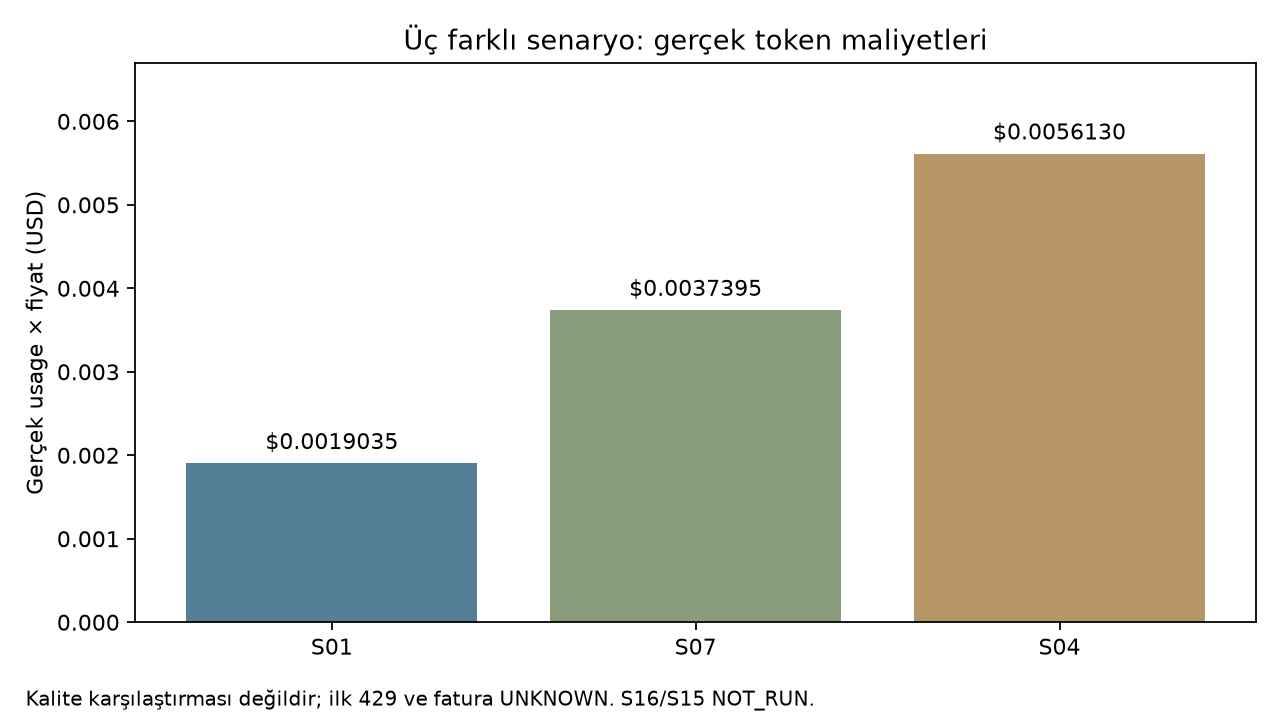

In [3]:
display(pd.DataFrame(json.loads((Q/'scenario_statuses.json').read_text(encoding='utf-8'))))
print((Q/'S16_frozen_context.json').read_text(encoding='utf-8'))
display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))
print((Q/'budget_plan.json').read_text(encoding='utf-8'))
display(Image(filename=str(ROOT/'reports/figures/WP12/openai_small_pilot_consolidation_v1/01_real_completed_token_costs.png')))


**S16 yorumu:** Kaynak yoktur; beklenen ret NO_SOURCE ve boş items. IMAGE_TEXT_UNAVAILABLE S15’in ayrı koşuludur. S16 için schema yanlış ret kodlarını da kaydedebilir; uygulama kontrolü doğru gerekçeyi ayrıca denetler. Ret JSON’unda serbest Türkçe açıklama yoksa Türkçe anlatım kalitesi NOT_EVALUABLE kalır; language=tr kalite kanıtı değildir. Test yanıtları TEST_ONLY ve gerçek sonuç değildir. Exact token sayımı API önkontrolünde yapılacaktır; bağlam kesilmez. 12/4/.092 rezerv aynı, S16 tamamlanırsa15/5/.115; tavan30/10/.25. İlk429 bilinmeyen maliyet sıfırlanmaz. İnsan incelemesi, gerçek S16 sonrasında ayrı yapılır. S15,19×3,yayın,eğitim ve WP13 kodu başlamaz.